# Этап 3. Часть 2 - Предобработка

**Датасет:** Students Performance in Exams (Kaggle, автор spscientist)

**План:**
1. Загрузка и очистка данных
2. Масштабирование одного числового признака тремя методами
3. Графики распределения до и после каждого преобразования
4. Сравнение методов и выбор лучшего
5. Разделение на train/test (80/20) и предобработка всех столбцов
6. Вывод

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer

## 1. Загрузка и очистка данных

Очистка та же, что в Части 1: удаляю полные дубликаты, пропуски (включая текстовые маркеры) и строки с логическими ошибками - оценки вне 0-100 и недопустимые категории. Подробное обоснование каждого шага - в ноутбуке Части 1.

In [2]:
RAW_PATH = '../data/raw/StudentsPerformance.csv'
RAW_URL = 'https://raw.githubusercontent.com/arsenijchekin-a11y/icp-students-performance/main/data/raw/StudentsPerformance.csv'

if os.path.exists(RAW_PATH):
    source = RAW_PATH
else:
    source = RAW_URL

df = pd.read_csv(source, sep=None, engine='python')

df = df.rename(columns={
    'race/ethnicity': 'race_ethnicity',
    'parental level of education': 'parent_education',
    'test preparation course': 'test_prep',
    'math score': 'math_score',
    'reading score': 'reading_score',
    'writing score': 'writing_score'
})

score_cols = ['math_score', 'reading_score', 'writing_score']
cat_cols = ['gender', 'race_ethnicity', 'parent_education', 'lunch', 'test_prep']
print('Исходный размер:', df.shape)

Исходный размер: (1000, 8)


In [3]:
markers = ['', 'nan', 'NaN', 'NA', 'N/A', '-', '?', 'нет данных']

allowed = {
    'gender': ['female', 'male'],
    'race_ethnicity': ['group A', 'group B', 'group C', 'group D', 'group E'],
    'parent_education': ['some high school', 'high school', 'some college',
                         "associate's degree", "bachelor's degree", "master's degree"],
    'lunch': ['standard', 'free/reduced'],
    'test_prep': ['none', 'completed']
}

# 1) дубликаты
print('Дубликатов:', df.duplicated().sum())
df = df.drop_duplicates()

# 2) пропуски
for col in cat_cols:
    df[col] = df[col].astype(str).str.strip()
    df[col] = df[col].replace(markers, np.nan)
print('Пропусков:', df.isna().sum().sum())
df = df.dropna()

# 3) логические ошибки
bad = pd.Series(False, index=df.index)
for col in score_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    bad = bad | df[col].isna() | (df[col] < 0) | (df[col] > 100)
for col in cat_cols:
    bad = bad | ~df[col].isin(allowed[col])
print('Строк с логическими ошибками:', bad.sum())
df = df[~bad]

print('Размер после очистки:', df.shape)

Дубликатов: 0
Пропусков: 0
Строк с логическими ошибками: 0
Размер после очистки: (1000, 8)


Ошибок нет, все 1000 строк остаются.

## 2. Масштабирование признака `reading_score`

Для сравнения методов беру **оценку по чтению** (`reading_score`). Это числовой признак, который пойдёт во входные данные модели. Целевую переменную `math_score` не беру: её масштабировать не нужно (подробнее в разделе 5).

У `reading_score` есть 6 низких выбросов (найдены в Этапе 2), поэтому на нём хорошо видно, как разные методы реагируют на выбросы.

Сравниваю три метода:
- **MinMaxScaler** - сжимает значения в диапазон от 0 до 1: `(x - min) / (max - min)`;
- **StandardScaler** - стандартизация: среднее 0, стандартное отклонение 1: `(x - среднее) / std`;
- **RobustScaler** - устойчивое масштабирование: медиана 0, межквартильный размах 1: `(x - медиана) / IQR`.

Здесь методы применяются ко всему столбцу только для того, чтобы сравнить их между собой. Для модели масштабирование обучается только на train - это сделано в разделе 5.

In [4]:
x = df[['reading_score']]

scaled = {
    'Исходные данные': x['reading_score'].values,
    'MinMaxScaler': MinMaxScaler().fit_transform(x).ravel(),
    'StandardScaler': StandardScaler().fit_transform(x).ravel(),
    'RobustScaler': RobustScaler().fit_transform(x).ravel()
}

## 3. Графики распределения до и после преобразований

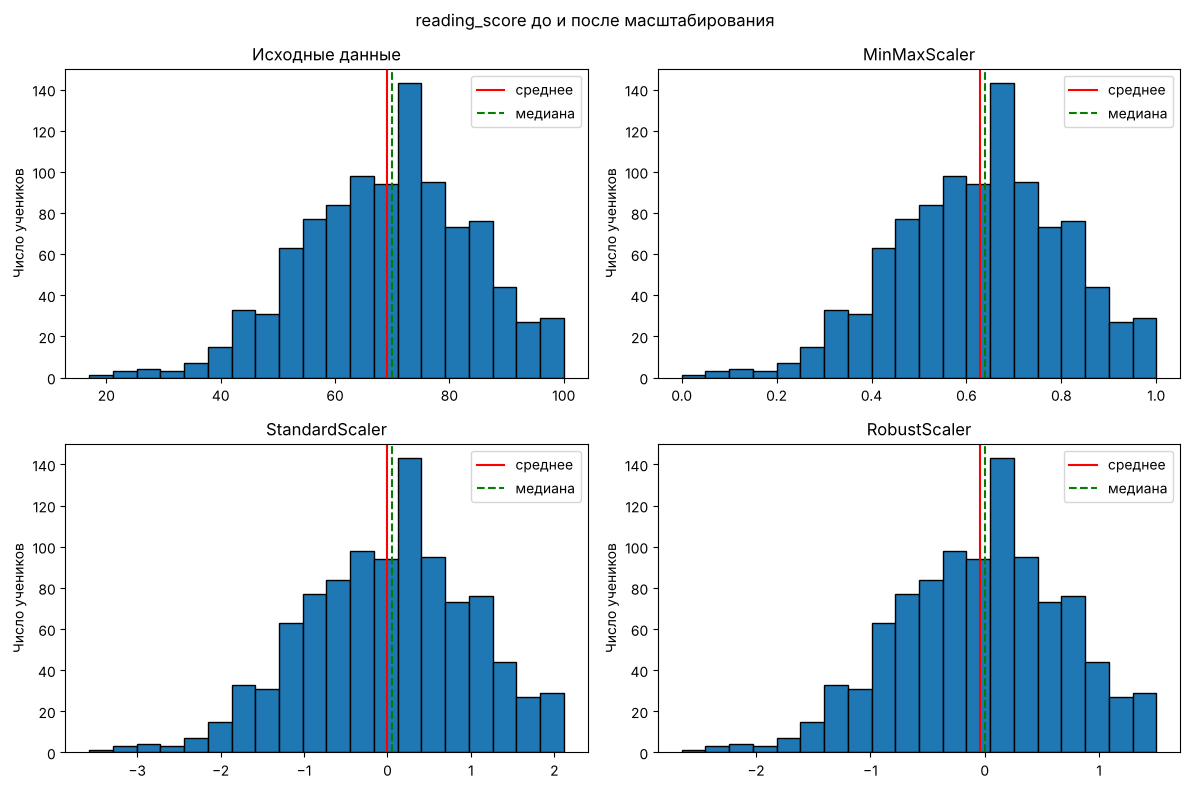

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for i, (name, values) in enumerate(scaled.items()):
    axes[i].hist(values, bins=20, edgecolor='black')
    axes[i].axvline(np.mean(values), color='red', label='среднее')
    axes[i].axvline(np.median(values), color='green', linestyle='--', label='медиана')
    axes[i].set_title(name)
    axes[i].set_ylabel('Число учеников')
    axes[i].legend()

plt.suptitle('reading_score до и после масштабирования')
plt.tight_layout()
plt.show()

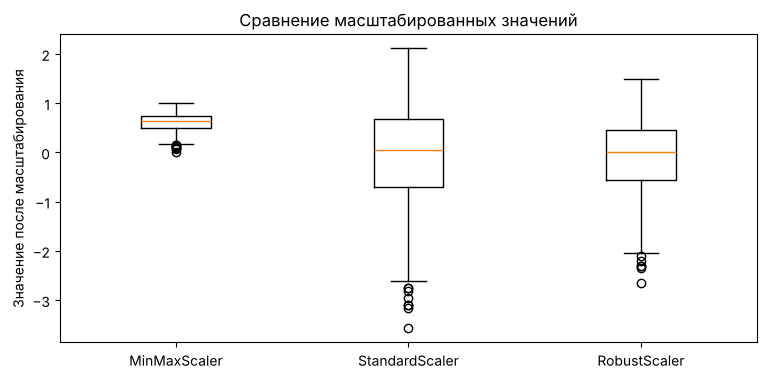

In [6]:
# boxplot на одной шкале - видно, где оказываются выбросы после каждого метода
plt.figure(figsize=(9, 4))
plt.boxplot([scaled['MinMaxScaler'], scaled['StandardScaler'], scaled['RobustScaler']])
plt.xticks([1, 2, 3], ['MinMaxScaler', 'StandardScaler', 'RobustScaler'])
plt.title('Сравнение масштабированных значений')
plt.ylabel('Значение после масштабирования')
plt.show()

In [7]:
rows = []
for name, values in scaled.items():
    s = pd.Series(values)
    rows.append({
        'Метод': name,
        'Мин': round(s.min(), 2),
        'Макс': round(s.max(), 2),
        'Среднее': round(s.mean(), 2),
        'Медиана': round(s.median(), 2),
        'Ст. отклонение': round(s.std(), 2),
        'IQR': round(s.quantile(0.75) - s.quantile(0.25), 2),
        'Асимметрия': round(s.skew(), 3)
    })

pd.DataFrame(rows)

,Метод,Мин,Макс,Среднее,Медиана,Ст. отклонение,IQR,Асимметрия
0,Исходные данные,17.00,100.00,69.17,70.00,14.60,20.00,-0.259
1,MinMaxScaler,0.00,1.00,0.63,0.64,0.18,0.24,-0.259
2,StandardScaler,-3.57,2.11,0.00,0.06,1.00,1.37,-0.259
3,RobustScaler,-2.65,1.50,-0.04,0.00,0.73,1.00,-0.259


## 4. Различия между методами и выбор

**Что общего.** Все три метода - линейные преобразования: они сдвигают и растягивают шкалу, но не меняют форму распределения. Поэтому гистограммы выглядят одинаково, а асимметрия у всех одна и та же (-0.259). Выбросы ни один метод не убирает - меняется только то, где они оказываются на шкале.

**Чем различаются:**

| Метод | Результат для `reading_score` | Влияние выбросов |
|---|---|---|
| MinMaxScaler | диапазон 0-1, основная масса учеников сжата примерно в 0.5-0.8 | сильное: минимум (17 баллов, выброс) задаёт ноль шкалы, поэтому основная масса «съезжает» вправо |
| StandardScaler | среднее 0, стандартное отклонение 1, диапазон от -3.57 до 2.11 | среднее: выбросы влияют на среднее и стандартное отклонение, хотя и слабее, чем на min и max |
| RobustScaler | медиана 0, IQR 1, диапазон от -2.65 до 1.5 | слабое: медиана и IQR считаются по центральной части данных и почти не зависят от крайних значений |

**Выбор - RobustScaler.** В Этапе 2 я решил не удалять выбросы, потому что они правдоподобны. Значит, метод масштабирования должен быть к ним устойчив. RobustScaler строит шкалу по медиане и межквартильному размаху: несколько очень низких оценок не сдвигают её, и основная масса учеников остаётся в центре шкалы. MinMaxScaler здесь хуже всего, потому что вся шкала зависит от одного минимального значения. StandardScaler тоже подошёл бы, так как распределение близко к нормальному, но он всё же чувствителен к выбросам.

## 5. Разделение на train/test и предобработка всех столбцов

**Целевая переменная** - `math_score` (как в Этапе 1). Все остальные столбцы - входные признаки.

**Почему сначала разделение, потом предобработка.** Если обучить масштабирование или кодирование на всём датасете, в train «просочится» информация о test (например, его медиана и IQR). Это утечка данных: оценка модели на test окажется завышенной. Поэтому все преобразования обучаются (`fit`) только на train, а к test только применяются (`transform`).

**Параметры разбиения:**
- 80% train / 20% test, `random_state=42` - чтобы разбиение повторялось;
- `stratify` по метке «сдал / не сдал» (порог 60 баллов): так в train и test одинаковая доля несдавших, 68/32 (дисбаланс из Этапа 2).

In [8]:
X = df.drop(columns='math_score')
y = df['math_score']

pass_label = (y >= 60).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=pass_label
)

print('train:', X_train.shape, ' test:', X_test.shape)
print('Доля сдавших в train:', round((y_train >= 60).mean(), 3))
print('Доля сдавших в test: ', round((y_test >= 60).mean(), 3))

train: (800, 7)  test: (200, 7)
Доля сдавших в train: 0.678
Доля сдавших в test:  0.675


**Выбор метода для каждого столбца:**

| Столбец | Тип | Метод | Почему |
|---|---|---|---|
| `reading_score`, `writing_score` | число | RobustScaler | выбор из раздела 4: устойчив к низким выбросам, которые мы сохранили |
| `parent_education` | порядковая категория | OrdinalEncoder (0-5) | уровни образования упорядочены от неоконченной школы до магистратуры, порядковый код этот порядок сохраняет |
| `race_ethnicity` | категория без порядка | OneHotEncoder | группы A-E не имеют порядка; если закодировать их числами 0-4, модель решит, что «E больше A». One-hot делает отдельный столбец 0/1 для каждой группы |
| `gender`, `lunch`, `test_prep` | бинарная категория | OneHotEncoder (`drop='if_binary'`) | у признака два значения, поэтому достаточно одного столбца 0/1 - второй был бы лишним дублем |
| `math_score` (цель) | число | не преобразуется | целевую переменную оставляем в баллах, чтобы прогноз и ошибка модели были понятны (например, «ошибка 5 баллов») |

`handle_unknown='ignore'` нужен на случай, если в test встретится категория, которой не было в train: тогда кодировщик не упадёт с ошибкой.

In [9]:
edu_order = ['some high school', 'high school', 'some college',
             "associate's degree", "bachelor's degree", "master's degree"]

preprocessor = ColumnTransformer([
    ('scores', RobustScaler(), ['reading_score', 'writing_score']),
    ('education', OrdinalEncoder(categories=[edu_order]), ['parent_education']),
    ('race', OneHotEncoder(handle_unknown='ignore'), ['race_ethnicity']),
    ('binary', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), ['gender', 'lunch', 'test_prep'])
])

# обучение только на train, применение к train и test
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

feature_names = [name.split('__')[1] for name in preprocessor.get_feature_names_out()]

X_train_prep = pd.DataFrame(X_train_prep, columns=feature_names, index=X_train.index)
X_test_prep = pd.DataFrame(X_test_prep, columns=feature_names, index=X_test.index)

print('Признаков после предобработки:', X_train_prep.shape[1])
X_train_prep.head()

Признаков после предобработки: 11


,reading_score,writing_score,parent_education,race_ethnicity_group A,race_ethnicity_group B,race_ethnicity_group C,race_ethnicity_group D,race_ethnicity_group E,gender_male,lunch_standard,test_prep_none
996,-0.681818,-0.636364,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
208,0.500000,0.318182,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
991,0.545455,0.409091,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
347,1.090909,1.181818,4.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
850,-0.136364,-0.090909,5.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0


**Проверка результата.** Медиана масштабированных оценок в train должна быть 0, а в test - близка к 0, но не обязательно равна ему: test преобразован по параметрам train. Пропусков после преобразования быть не должно.

In [10]:
print('Пропусков в train:', X_train_prep.isna().sum().sum())
print('Пропусков в test: ', X_test_prep.isna().sum().sum())
print()
print('Медианы масштабированных оценок:')
print(pd.DataFrame({
    'train': X_train_prep[['reading_score', 'writing_score']].median().round(3),
    'test': X_test_prep[['reading_score', 'writing_score']].median().round(3)
}))

Пропусков в train: 0
Пропусков в test:  0

Медианы масштабированных оценок:
               train   test
reading_score    0.0  0.045
writing_score    0.0  0.023


In [11]:
# сохраняем подготовленные данные вместе с целевой переменной
train_out = X_train_prep.copy()
train_out['math_score'] = y_train
test_out = X_test_prep.copy()
test_out['math_score'] = y_test

out_dir = '../data/processed'
if not os.path.exists(out_dir):
    out_dir = '.'   # в Colab папки data нет - сохраняем рядом с ноутбуком

train_out.to_csv(f'{out_dir}/train_processed.csv', index=False)
test_out.to_csv(f'{out_dir}/test_processed.csv', index=False)
print('Сохранено в', out_dir)

Сохранено в ../data/processed


## 6. Вывод

1. **Очистка:** дубликатов, пропусков и логических ошибок нет, все 1000 строк используются.
2. **Масштабирование:** все три метода линейные и не меняют форму распределения. Различие в том, как они строят шкалу: MinMaxScaler зависит от минимума и максимума и сильнее всего страдает от выбросов, StandardScaler - от среднего и стандартного отклонения, RobustScaler - от медианы и IQR. Для `reading_score` с низкими выбросами лучший выбор - **RobustScaler**.
3. **Предобработка:** выборка разделена на train/test 80/20 со стратификацией по «сдал / не сдал». Все преобразования обучены только на train, чтобы не было утечки данных. Оценки масштабированы RobustScaler, образование родителей закодировано по порядку, остальные категории - через one-hot. Целевая переменная `math_score` оставлена в баллах.
4. **Результат:** 11 признаков без пропусков, готовые для обучения модели. Файлы сохранены в `data/processed/train_processed.csv` и `data/processed/test_processed.csv`.